# Previsão de Valor de Aluguel com Regressão Linear

Modelo de Machine Learning para prever o valor do aluguel de um imóvel a partir de suas características: análise exploratória, preparação de dados, construção do modelo, avaliação e interpretação dos resultados.

## 1. Análise exploratória dos dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
df = pd.read_csv("dataset_aluguel.csv")
df = df.drop(columns=["id"])
df.head()

,tamanho_m2,n_quartos,idade_casa,garagem,localizacao_Periferia,localizacao_Subúrbio,valor_aluguel
0,106.181018,1,36.760806,0,True,False,1767.122088
1,192.607146,4,10.453581,1,True,False,3278.742397
2,159.799091,5,27.072399,1,True,False,2953.899737
3,139.798773,4,34.789220,1,False,True,2514.717108
4,73.402796,5,11.427501,0,False,True,1942.164396


In [3]:
print("Linhas e colunas:", df.shape)
df.info()

Linhas e colunas: (100, 7)
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tamanho_m2             100 non-null    float64
 1   n_quartos              100 non-null    int64  
 2   idade_casa             100 non-null    float64
 3   garagem                100 non-null    int64  
 4   localizacao_Periferia  100 non-null    bool   
 5   localizacao_Subúrbio   100 non-null    bool   
 6   valor_aluguel          100 non-null    float64
dtypes: bool(2), float64(3), int64(2)
memory usage: 4.2 KB


In [4]:
df.describe()

,tamanho_m2,n_quartos,idade_casa,garagem,valor_aluguel
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,120.527112,2.910000,25.794810,0.520000,2112.819084
std,44.623412,1.400541,14.348628,0.502117,514.314100
min,50.828318,1.000000,0.259243,0.000000,1192.728727
25%,78.980114,1.750000,13.969405,0.000000,1694.633091
50%,119.621368,3.000000,24.827177,1.000000,2069.395680
75%,159.530468,4.000000,37.252879,1.000000,2520.182679
max,198.033040,5.000000,49.812685,1.000000,3278.742397


In [5]:
print("Valores nulos por coluna:")
df.isnull().sum()

Valores nulos por coluna:


tamanho_m2               0
n_quartos                0
idade_casa               0
garagem                  0
localizacao_Periferia    0
localizacao_Subúrbio     0
valor_aluguel            0
dtype: int64

## Distribuição das variáveis

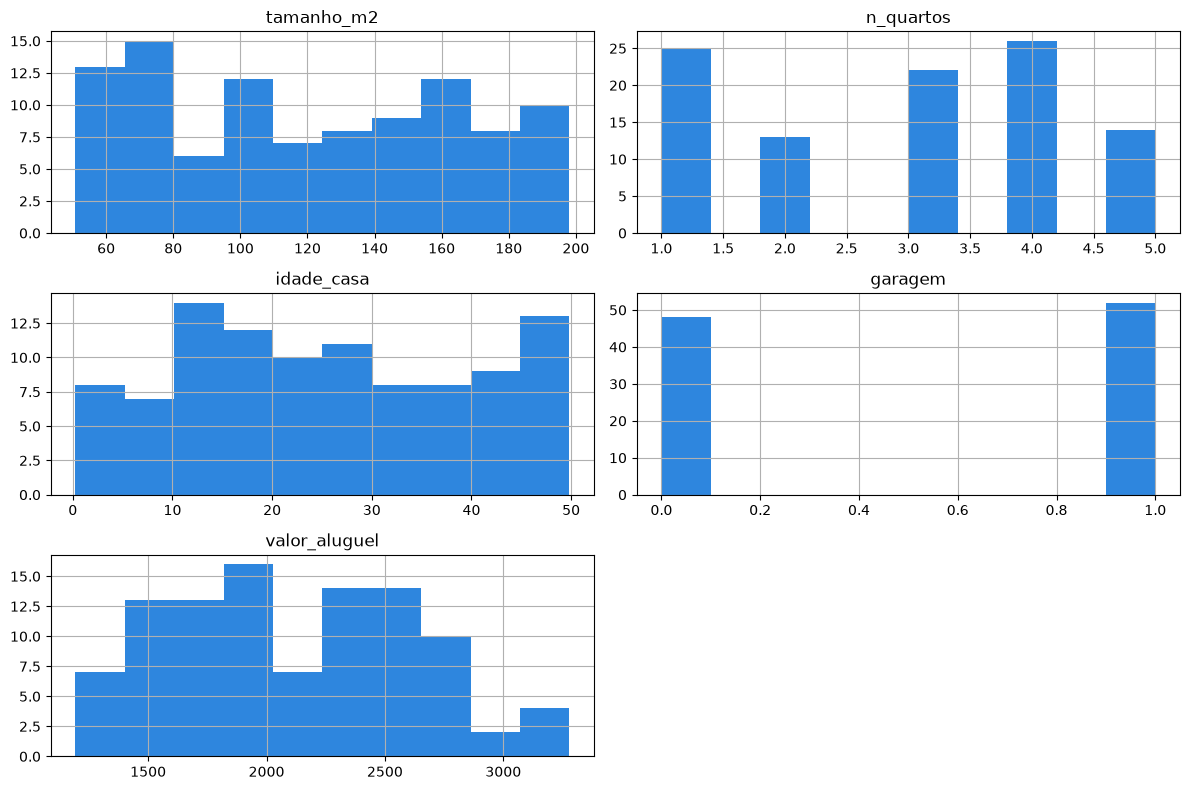

In [6]:
df.hist(figsize=(12, 8), color="#2E86DE")
plt.tight_layout()
plt.show()

### Outliers (boxplot)

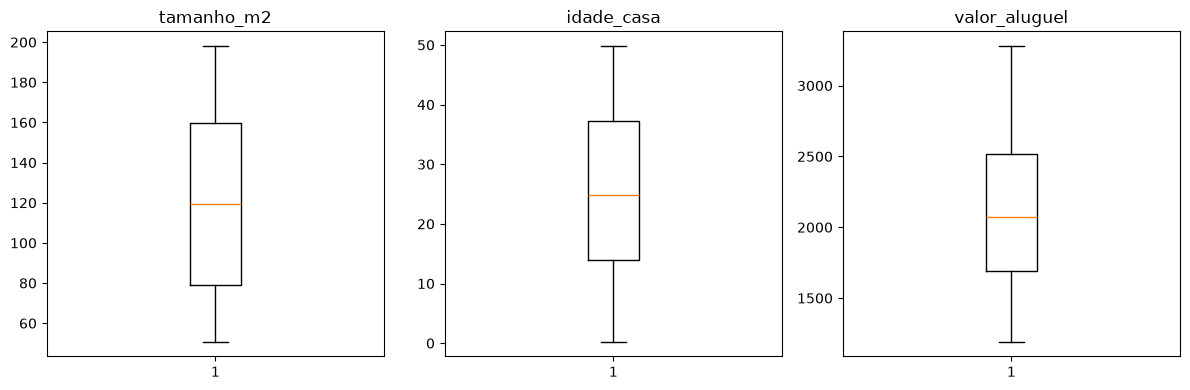

In [7]:
colunas = ["tamanho_m2", "idade_casa", "valor_aluguel"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, colunas):
    ax.boxplot(df[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 2. Preparação dos dados

Não há valores ausentes. A localização já vem codificada (one-hot) nas colunas booleanas, que convertemos para 0 e 1.

In [8]:
colunas_bool = df.select_dtypes(include='bool').columns
df[colunas_bool] = df[colunas_bool].astype(int)
df.head()

,tamanho_m2,n_quartos,idade_casa,garagem,localizacao_Periferia,localizacao_Subúrbio,valor_aluguel
0,106.181018,1,36.760806,0,1,0,1767.122088
1,192.607146,4,10.453581,1,1,0,3278.742397
2,159.799091,5,27.072399,1,1,0,2953.899737
3,139.798773,4,34.789220,1,0,1,2514.717108
4,73.402796,5,11.427501,0,0,1,1942.164396


### Correlação entre as variáveis

In [9]:
df.corr().round(3)

,tamanho_m2,n_quartos,idade_casa,garagem,localizacao_Periferia,localizacao_Subúrbio,valor_aluguel
tamanho_m2,1.000,0.159,-0.057,-0.092,0.058,-0.092,0.896
n_quartos,0.159,1.000,0.050,0.067,0.056,0.111,0.449
idade_casa,-0.057,0.050,1.000,0.084,-0.112,-0.007,-0.178
garagem,-0.092,0.067,0.084,1.000,0.198,-0.196,0.088
localizacao_Periferia,0.058,0.056,-0.112,0.198,1.000,-0.509,0.277
localizacao_Subúrbio,-0.092,0.111,-0.007,-0.196,-0.509,1.000,-0.036
valor_aluguel,0.896,0.449,-0.178,0.088,0.277,-0.036,1.000


## 3. Construção do modelo

In [10]:
X = df.drop(columns=["valor_aluguel"])
y = df["valor_aluguel"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Treino:", X_train.shape[0], "| Teste:", X_test.shape[0])

Treino: 80 | Teste: 20


In [12]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 10.04, 99.73, -4.34,147.97,295.38,176.76]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['tamanho_m2','n_quartos','idade_casa','garagem','localizacao_Periferia', 'localizacao_Subúrbio']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,495.9
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


## 4. Avaliação do modelo

In [13]:
y_pred = modelo.predict(X_test)
print("R2:", round(r2_score(y_test, y_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("MSE:", round(mean_squared_error(y_test, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))


R2: 0.9907
MAE: 38.46
MSE: 2295.05
RMSE: 47.91


### Análise dos resíduos

Se os resíduos estiverem distribuídos de forma aleatória em torno de zero, o modelo linear é adequado.

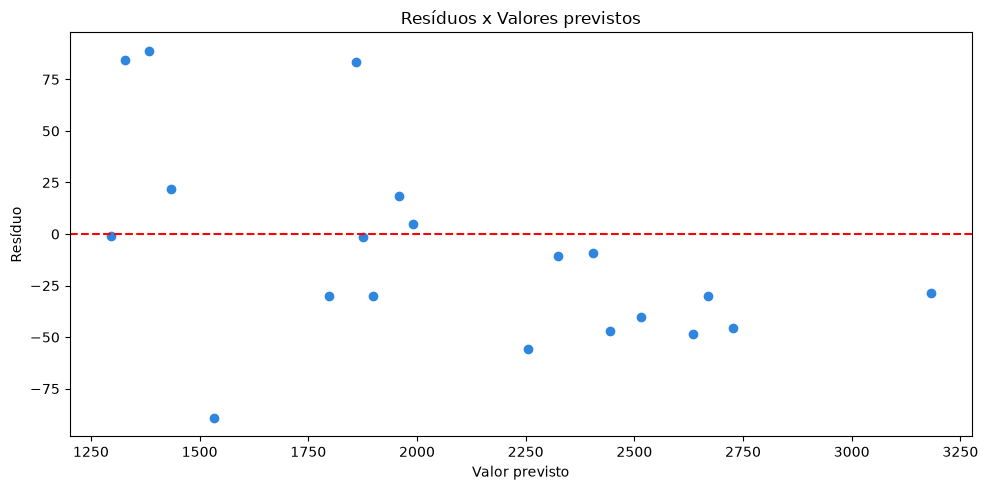

In [14]:
residuos = y_test - y_pred
plt.figure(figsize=(10, 5))
plt.scatter(y_pred, residuos, color="#2E86DE")
plt.axhline(0, color="red", linestyle="--")
plt.title("Resíduos x Valores previstos")
plt.xlabel("Valor previsto")
plt.ylabel("Resíduo")
plt.tight_layout()
plt.show()

## 5. Interpretação dos coeficientes 

Cada coeficiente indica quanto o valor do aluguel muda quando a variável aumenta em uma unidade, mantendo as demais constantes.

In [15]:
coeficientes = pd.DataFrame({
    "variavel": X.columns,
    "coeficiente": modelo.coef_
}).sort_values("coeficiente", ascending=False)

print("Intercepto:", round(modelo.intercept_, 2))
coeficientes

Intercepto: 495.92


,variavel,coeficiente
4,localizacao_Periferia,295.381661
5,localizacao_Subúrbio,176.758043
3,garagem,147.969526
1,n_quartos,99.728076
0,tamanho_m2,10.038814
2,idade_casa,-4.340694


## Conclusões

- O modelo de regressão linear alcançou R² de cerca de 0,99, explicando quase toda a variação do valor do aluguel, com erro médio (MAE) de aproximadamente R$ 38.
- As variáveis que mais aumentam o aluguel são o número de quartos (cerca de +R$ 100 por quarto) e a garagem (cerca de +R$ 148), além do tamanho (cerca de +R$ 10 por m²).
- A idade do imóvel tem efeito negativo: quanto mais velho, um pouco mais barato.
- Os resíduos distribuídos aleatoriamente em torno de zero indicam que a regressão linear é adequada para este conjunto de dados.